# Chapter 9 · Graph Data: Networks, GPU `PageRank`, `GraphRAG` & Classical Graph ML (`vkgraph`)

So far we have mastered **Tabular** (Ch. 1–2), **Image** (Ch. 3–4), **Vector/Text** (Ch. 5–6), and **Time-Series** (Ch. 7–8) data. Now we explore a 5th foundational AI data type that powers **Google Search, social networks, fraud detection, drug discovery, and `GraphRAG`**: **Graph Data**!

### What Is a Graph (In Plain English)?
A **Graph** is simply a web of **connections** made of two ingredients:
- **Nodes (Vertices):** The *things* — people, research papers, bank accounts, or molecules. Each node can also carry its own features (like a paper's vocabulary words).
- **Edges (Links):** The *relationships* between them — *"Alice is friends with Bob"* or *"Paper A cites Paper B"*.
- **Adjacency Matrix (`A`):** How a GPU thinks about a graph! It is an `N × N` grid where `A[i, j] = 1` if node `i` connects to node `j` (and `0` otherwise). Turning a network into matrix `A` lets your Vulkan GPU run `PageRank`, `Label Propagation`, and Graph Neural Networks at blazing speed using matrix multiplication!

### Two Real-World Graphs in This Chapter
1. **Visual Warm-Up — Zachary's Karate Club (34 people, 78 friendships):** Small enough to draw every single person and friendship so you can *literally see* **`PageRank`**, **`BFS` Shortest Path**, and **Community Detection** in action.
2. **Main Dataset — The Cora AI Citation Network (2,708 real papers, 5,429 citations, 7 AI topics):** Watch how ignoring citations stalls a classifier at ~`64%`, while using the graph jumps straight to **`85.5%`**!

> **Where Graph AI Is Used in the Real World:**
> - **Companies & Products:** Web ranking (**Google `PageRank`**), friend & pin recommendations (**LinkedIn, Pinterest `PinSage`, Uber Eats**), payment fraud rings (**PayPal, Visa**), and `GraphRAG` / molecular drug discovery.
> - **Popular Algorithms:** `PageRank`, `BFS` shortest paths, `Label Propagation` (this chapter), and Graph Neural Networks (**`GCN`, GraphSAGE, GAT** — Chapter 10!).

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Vulkan GPU ready: AMD Custom GPU 0405 (RADV VANGOGH)


Nodes,Edges,Avg Degree,Max Degree,Density,Node Features
34,78,4.59,17,0.1390,None


Top 3 most influential members (GPU PageRank): [(33, 0.101), (0, 0.097), (32, 0.072)]
Shortest path 16 -> 26 (5 hops): 16 -> 5 -> 0 -> 8 -> 33 -> 26
GPU Label Propagation from just 2 labeled leaders -> 100.0% of the club recovered!



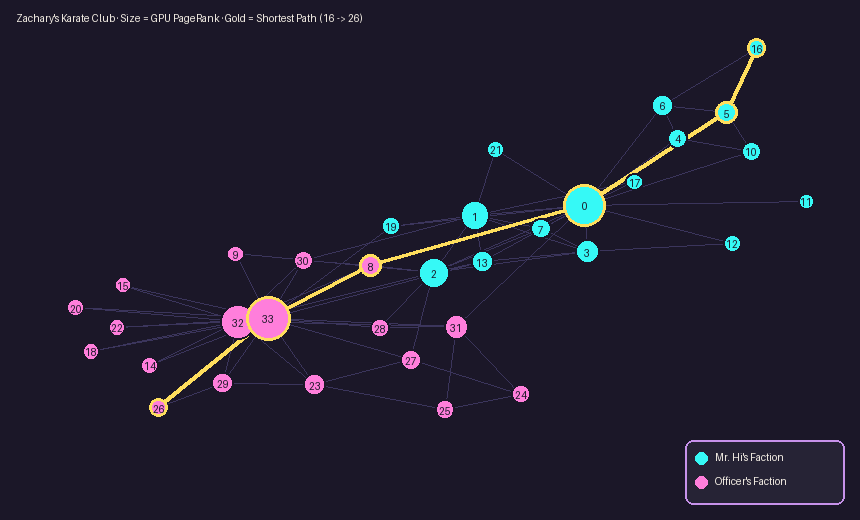

In [1]:
import sys, time
from pathlib import Path
from IPython.display import display

for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (p / "vknumpy").is_dir() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import vknumpy as vnp
import vklearn as vkl
import vkgraph

print(f"Vulkan GPU ready: {vnp.device_info()['name']}")

# 1. Visual Warm-Up: Zachary's Karate Club (34 members, 78 friendships, 2 real factions)
karate, factions = vkgraph.karate_club()
display(karate.describe())

# GPU PageRank: finds the most influential members (bigger circle = higher PageRank!)
pr_k = karate.pagerank()
top3 = sorted(range(len(karate)), key=lambda i: float(pr_k[i]), reverse=True)[:3]
print("Top 3 most influential members (GPU PageRank):", [(i, round(float(pr_k[i]), 3)) for i in top3])

# BFS Shortest Path: fewest friendship hops from member 16 to member 26
path = karate.shortest_path(16, 26)
print(f"Shortest path 16 -> 26 ({len(path)-1} hops): {' -> '.join(map(str, path))}")

# GPU Label Propagation: given ONLY the 2 club leaders (0 = Mr. Hi, 33 = Officer), predict everyone else's faction!
seeds = [-1] * len(karate)
seeds[0], seeds[33] = 0, 1
lp_k = karate.label_propagation(seeds, num_classes=2)
print(f"GPU Label Propagation from just 2 labeled leaders -> {float(vkl.accuracy_score(factions, lp_k))*100:.1f}% of the club recovered!\n")

display(vkgraph.render_graph(
    karate, labels=factions, node_sizes=pr_k, highlight_path=path,
    class_names=["Mr. Hi's Faction", "Officer's Faction"],
    title="Zachary's Karate Club · Size = GPU PageRank · Gold = Shortest Path (16 -> 26)",
))


---
### Step 1 · Scaling Up: The Real Cora AI Citation Network (2,708 Papers, 5,429 Citations)

Now let's load the famous **Cora Citation Network** in one line with `vkgraph.load_cora()`. Each of the 2,708 nodes is a real machine learning paper with a **1,433-word** feature vector and 1 of **7 AI topics**, and each edge means one paper cited another.

Let's inspect the graph, find the most cited/influential papers via **GPU `PageRank`**, and run a **`GraphRAG` `k_hop_neighbors`** query to pull a paper's 1-hop and 2-hop citation neighborhood!

In [2]:
cora, y_all, CLASS_NAMES = vkgraph.load_cora("data/cora")
display(cora.describe())
print("7 AI Research Topics:", ", ".join(CLASS_NAMES))

# GPU PageRank: find the 5 most influential hub papers in the citation network
t0 = time.perf_counter()
pr_cora = cora.pagerank()
ms_pr = (time.perf_counter() - t0) * 1000.0
top5 = sorted(range(len(cora)), key=lambda i: float(pr_cora[i]), reverse=True)[:5]
deg_cora = cora.degree()

print(f"\nTop 5 Most Influential Papers (GPU PageRank in {ms_pr:.1f} ms):")
for rank, idx in enumerate(top5, 1):
    m = cora.node_metadata[idx]
    print(f"  #{rank}  paper_id={m['paper_id']:7s} | topic={m['topic']:22s} | citations={int(deg_cora[idx]):3d} | PageRank={float(pr_cora[idx]):.4f}")

# GraphRAG k-hop retrieval: start from the #1 hub paper and fetch its 1-hop & 2-hop citation neighborhood!
hub = top5[0]
hops = cora.k_hop_neighbors(hub, k=2)
n_1hop = sum(1 for d in hops.values() if d == 1)
n_2hop = sum(1 for d in hops.values() if d == 2)
print(f"\nGraphRAG Neighborhood around Hub #{top5[0]} ({cora.node_metadata[hub]['topic']}): {n_1hop} direct 1-hop citations, {n_2hop} 2-hop related papers!")


Nodes,Edges,Avg Degree,Max Degree,Density,Node Features
"2,708","5,429",3.90,168,0.0015,1433-D float32


7 AI Research Topics: Case_Based, Genetic_Algorithms, Neural_Networks, Probabilistic_Methods, Reinforcement_Learning, Rule_Learning, Theory



Top 5 Most Influential Papers (GPU PageRank in 125.6 ms):
  #1  paper_id=35      | topic=Genetic_Algorithms     | citations=168 | PageRank=0.0122
  #2  paper_id=1365    | topic=Neural_Networks        | citations= 74 | PageRank=0.0062
  #3  paper_id=3229    | topic=Neural_Networks        | citations= 65 | PageRank=0.0053
  #4  paper_id=6213    | topic=Reinforcement_Learning | citations= 78 | PageRank=0.0051
  #5  paper_id=910     | topic=Neural_Networks        | citations= 44 | PageRank=0.0036

GraphRAG Neighborhood around Hub #163 (Genetic_Algorithms): 168 direct 1-hop citations, 257 2-hop related papers!


---
### Step 2 · Why Graphs Beat Plain Tables: Classical ML vs. GPU Label Propagation

Let's split the 2,708 papers **60% train / 40% test** (`vkl.train_test_split`, `random_state=42` — exact same split used in Chapter 10!) and race three approaches:
1. **Paper Words Only (`vklearn.Ridge`):** Ignores citations completely — treats the dataset like a plain table.
2. **Graph-Smoothed Features (`A_hat @ A_hat @ X` + `vklearn.Ridge`):** Before running Ridge, each paper averages its word vector with its 1-hop & 2-hop cited neighbors on GPU!
3. **Citations Only (`vkgraph.label_propagation` on GPU):** Ignores words completely — lets each unlabeled paper inherit topics from its citation neighborhood!

In [3]:
idx_all = vnp.arange(len(cora))
tr_idx, te_idx = vkl.train_test_split(idx_all, test_size=0.4, random_state=42)
tr_list = [int(i) for i in tr_idx.to_numpy()]
te_list = [int(i) for i in te_idx.to_numpy()]
y_tr = vnp.take(y_all, tr_idx, axis=0)
y_te = vnp.take(y_all, te_idx, axis=0)

def ovr_ridge_acc(X_gpu, alpha=0.1):
    Xtr, Xte = vnp.take(X_gpu, tr_idx, axis=0), vnp.take(X_gpu, te_idx, axis=0)
    cols = []
    for c in range(len(CLASS_NAMES)):
        yc = (y_tr == c).astype(float)
        cols.append(vkl.Ridge(alpha=alpha).fit(Xtr, yc).predict(Xte))
    preds = vnp.argmax(vnp.column_stack(cols), axis=1)
    return float(vkl.accuracy_score(y_te, preds))

# 1. Words Only (ignores citations!)
t0 = time.perf_counter()
acc_words = ovr_ridge_acc(cora.features, alpha=0.5)
dt_words = time.perf_counter() - t0

# 2. Graph-Smoothed Features (A_hat @ A_hat @ X + Ridge)
t0 = time.perf_counter()
A_hat = cora.normalized_adjacency(add_self_loops=True)
X_smooth = A_hat @ (A_hat @ cora.features)
acc_smooth = ovr_ridge_acc(X_smooth, alpha=0.1)
dt_smooth = time.perf_counter() - t0

# 3. Citations Only (GPU Label Propagation)
t0 = time.perf_counter()
seeds = [-1] * len(cora)
for i in tr_list:
    seeds[i] = int(y_all[i])
lp_all = cora.label_propagation(seeds, num_classes=len(CLASS_NAMES))
acc_lp = float(vkl.accuracy_score(y_te, vnp.take(lp_all, te_idx, axis=0)))
dt_lp = time.perf_counter() - t0

print(f"{'Classical Graph ML Model (Cora · 1,083 Test Papers)':54s} | {'Test Acc':>8s} | {'Time':>6s}")
print("-" * 76)
for name, acc, dt in [
    ("1. Paper Words Only (Ridge, ignores citations)",     acc_words,  dt_words),
    ("2. Graph-Smoothed Words (A_hat^2 @ X + Ridge)",     acc_smooth, dt_smooth),
    ("3. Citations Only (GPU Label Propagation, Winner)", acc_lp,     dt_lp),
]:
    print(f"{name:54s} | {acc*100:7.2f}% | {dt:5.2f}s")
print(f"\nUsing the citation graph boosted accuracy by +{(acc_lp - acc_words)*100:.1f} points!")
print("Next in Chapter 10: combine BOTH words AND citations end-to-end with a vktorch Graph Convolutional Network (GCN)!")


Classical Graph ML Model (Cora · 1,083 Test Papers)    | Test Acc |   Time
----------------------------------------------------------------------------
1. Paper Words Only (Ridge, ignores citations)         |   71.47% |  1.07s
2. Graph-Smoothed Words (A_hat^2 @ X + Ridge)          |   87.17% |  1.04s
3. Citations Only (GPU Label Propagation, Winner)      |   85.50% |  0.29s

Using the citation graph boosted accuracy by +14.0 points!
Next in Chapter 10: combine BOTH words AND citations end-to-end with a vktorch Graph Convolutional Network (GCN)!
